# KA SS 26 — Challenge 2 · Cell Instance Segmentation
### Stage 1 notebook: EDA + corrected Mask R-CNN pipeline (end-to-end)

**How to run**

1. First pass: leave `CFG.SMOKE_TEST = True`. Runs full EDA + a 2-epoch pipeline validation +
   threshold sweep + a valid `submission.csv` in ~15 min. Nothing here is meant to score well.
2. Send back the notebook with outputs (everything important is also written to
   `/kaggle/working/artifacts/`).
3. Second pass: `SMOKE_TEST = False` → full training run.

**Design rules followed here**

- Nothing is assumed about: CSV schema, RLE flatten order, presence of `cell_type`, whether GT
  instances overlap, the exact metric aggregation, or pretrained-weight legality. Each is
  *detected* and printed, or exposed as a config flag and flagged loudly.
- The competition metric is implemented in one isolated cell with four candidate aggregations.
  Replace it with the official reference implementation when available.
- Single GPU + AMP. Deterministic seeds where PyTorch allows it.

## 0 · Environment, seeds, paths

In [1]:
import os
# Pin to a single GPU BEFORE torch is imported (T4 x2 -> use cuda:0 only)
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTHONHASHSEED"] = "42"

import sys, gc, json, time, math, random, warnings, shutil
from glob import glob
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision

warnings.filterwarnings("ignore")

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(42)
torch.backends.cudnn.benchmark = True
try:
    torch.set_float32_matmul_precision("high")
except Exception:
    pass

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ART = Path("/kaggle/working/artifacts"); ART.mkdir(parents=True, exist_ok=True)
CKPT = Path("/kaggle/working/ckpt"); CKPT.mkdir(parents=True, exist_ok=True)

print("python      :", sys.version.split()[0])
print("torch       :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("device      :", DEVICE)
if torch.cuda.is_available():
    print("gpu         :", torch.cuda.get_device_name(0),
          f"{torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
print("cpus        :", os.cpu_count())

python      : 3.12.13
torch       : 2.10.0+cu128
torchvision : 0.25.0+cu128
device      : cuda
gpu         : Tesla T4 15.6 GB
cpus        : 4


## 1 · Configuration

Everything tunable lives here. `SMOKE_TEST` shrinks the run so the whole pipeline executes in minutes.

In [2]:
class CFG:
    # ---------------- run mode ----------------
    SMOKE_TEST      = True     # <-- flip to False for the real run
    SEED            = 42

    # ---------------- data ----------------
    VAL_FRACTION    = 0.15
    IMG_H, IMG_W    = 520, 704   # verified below, not assumed
    RLE_ORDER       = "auto"     # "auto" | "C" | "F"  -> auto-detected in section 3

    # ---------------- metric ----------------
    # Aggregation used for checkpoint selection / threshold tuning.
    # "sum_over_max" | "f1" | "pq_like" | "mean_matched"
    PRIMARY_METRIC  = "sum_over_max"
    DICE_MATCH_THR  = 0.50

    # ---------------- model ----------------
    ARCH            = "v2"       # "v1" = maskrcnn_resnet50_fpn, "v2" = improved recipe
    # "coco"            -> full COCO-pretrained detector (what the official baseline uses)
    # "imagenet_bb"     -> ImageNet backbone only, detector heads from scratch (rules-safe)
    WEIGHTS_MODE    = "coco"
    TRAINABLE_BB_LAYERS = 5
    ANCHOR_SIZES    = "auto"     # "auto" -> derived from GT box stats | None -> torchvision default
    ASPECT_RATIOS   = "auto"     # "auto" -> derived from GT box aspect stats | None -> (0.5,1.0,2.0)
    MIN_SIZE_TRAIN  = (640, 704, 768, 800, 864)   # multi-scale short side
    MIN_SIZE_TEST   = 800
    MAX_SIZE        = 1400
    NORMALIZE_WITH_DATASET_STATS = True   # else ImageNet stats

    # detection capacity (auto-adjusted from instance-count stats)
    BOX_DET_PER_IMG   = 500
    RPN_PRE_TEST      = 4000
    RPN_POST_TEST     = 2000
    RPN_BATCH_PER_IMG = 256
    BOX_BATCH_PER_IMG = 512

    # ---------------- loss ----------------
    MASK_LOSS       = "bce+dice"  # "bce" | "bce+dice"
    BCE_W, DICE_W   = 1.0, 1.0

    # ---------------- optimisation ----------------
    EPOCHS          = 24
    BATCH_SIZE      = 2
    ACCUM_STEPS     = 2
    LR              = 1e-4
    BACKBONE_LR_MULT= 0.5
    WEIGHT_DECAY    = 1e-4
    WARMUP_STEPS    = 400
    GRAD_CLIP       = 5.0
    AMP             = True
    NUM_WORKERS     = 2
    EVAL_EVERY      = 1
    EVAL_START_EPOCH= 3
    MAX_INSTANCES_TRAIN = 600    # safety cap on GT instances per image (memory)
    MIN_GT_AREA     = 10         # drop degenerate GT instances

    # ---------------- augmentation ----------------
    AUG_HFLIP, AUG_VFLIP, AUG_ROT90 = 0.5, 0.5, 0.5
    AUG_BRIGHTNESS_CONTRAST = 0.5
    AUG_GAMMA       = 0.3
    AUG_NOISE       = 0.2

    # ---------------- inference / sweep ----------------
    EVAL_SCORE_THR    = 0.30     # quick threshold used for in-training eval only
    EVAL_MAX_DET      = 400
    CACHE_SCORE_THR   = 0.01     # keep almost everything, filter offline
    CACHE_MAX_DET     = 500
    SWEEP_MASK_THR    = (0.30, 0.40, 0.50, 0.60)
    SWEEP_SCORE_THR   = tuple(np.round(np.arange(0.05, 0.96, 0.05), 2))
    SWEEP_MIN_AREA_Q  = (0.0, 0.01, 0.05, 0.10)   # quantiles of GT area distribution
    PER_CLUSTER_THRESHOLDS = False   # reported either way; enable only if the gain is real

    # ---------------- clustering (cell-type proxy) ----------------
    CLUSTER_K_RANGE = (2, 3, 4, 5)

if CFG.SMOKE_TEST:
    CFG.EPOCHS = 2
    CFG.EVAL_START_EPOCH = 1
    CFG.MIN_SIZE_TRAIN = (704,)
    CFG.SWEEP_SCORE_THR = tuple(np.round(np.arange(0.1, 0.91, 0.1), 2))
    CFG.SWEEP_MASK_THR = (0.4, 0.5)
    CFG.SWEEP_MIN_AREA_Q = (0.0, 0.05)

seed_everything(CFG.SEED)
STATS = {}   # everything worth reporting back gets stashed here
print("SMOKE_TEST =", CFG.SMOKE_TEST, "| EPOCHS =", CFG.EPOCHS)

SMOKE_TEST = True | EPOCHS = 2


## 2 · Dataset discovery & schema validation

No hardcoded paths, no assumed column names.

In [3]:
# ---- locate the competition directory ----
CANDIDATES = glob("/kaggle/input/*/cells_segmentation") + glob("/kaggle/input/*/*/cells_segmentation")
if not CANDIDATES:
    CANDIDATES = [p for p in glob("/kaggle/input/*") if os.path.isdir(p)]
assert CANDIDATES, "Could not find the competition data under /kaggle/input"
BASE = Path(CANDIDATES[0])
print("BASE =", BASE)

print("\n--- top-level contents ---")
for p in sorted(BASE.iterdir()):
    if p.is_dir():
        n = len(list(p.glob('*')))
        print(f"  [dir ] {p.name:<32} {n} files")
    else:
        print(f"  [file] {p.name:<32} {p.stat().st_size/1e6:.2f} MB")

TRAIN_DIR = BASE / "train"
TEST_DIR  = BASE / "test"
UNLAB_DIR = BASE / "unlabeled_additional_data"
TRAIN_CSV = BASE / "train.csv"
for p in [TRAIN_DIR, TEST_DIR, TRAIN_CSV]:
    assert p.exists(), f"missing: {p}"

SAMPLE_SUB = None
for cand in list(BASE.glob("*ubmission*.csv")) + list(Path("/kaggle/input").rglob("*ample_submission*.csv")):
    SAMPLE_SUB = cand; break
print("\nsample_submission:", SAMPLE_SUB if SAMPLE_SUB else "NOT FOUND (will mirror train.csv schema)")

BASE = /kaggle/input/competitions/ka-ss-26-challenge-2/cells_segmentation

--- top-level contents ---
  [dir ] test                             182 files
  [dir ] train                            424 files
  [file] train.csv                        13.35 MB
  [dir ] unlabeled_additional_data        1972 files

sample_submission: NOT FOUND (will mirror train.csv schema)


In [4]:
# ---- train.csv schema: detect, do not assume ----
df_raw = pd.read_csv(TRAIN_CSV)
print("shape      :", df_raw.shape)
print("columns    :", df_raw.columns.tolist())
print("dtypes     :\n", df_raw.dtypes.to_string())
print("\nhead:\n", df_raw.head(3).to_string())

ID_COL  = next((c for c in df_raw.columns if c.lower() in ("id", "image_id", "imageid")), None)
ANN_COL = next((c for c in df_raw.columns if c.lower() in ("annotation", "encodedpixels", "rle", "segmentation")), None)
assert ID_COL and ANN_COL, f"could not identify id/annotation columns in {df_raw.columns.tolist()}"
OTHER_COLS = [c for c in df_raw.columns if c not in (ID_COL, ANN_COL)]

print(f"\nID_COL={ID_COL!r}  ANN_COL={ANN_COL!r}  OTHER={OTHER_COLS}")
for c in OTHER_COLS:
    nu = df_raw[c].nunique()
    looks_like_index = pd.api.types.is_integer_dtype(df_raw[c]) and nu == len(df_raw)
    print(f"  other column {c!r}: nunique={nu}, looks_like_row_index={looks_like_index}, "
          f"sample={df_raw[c].head(3).tolist()}")

CELL_TYPE_COL = next((c for c in OTHER_COLS
                      if df_raw[c].dtype == object and 1 < df_raw[c].nunique() <= 12), None)
HAS_CELL_TYPE = CELL_TYPE_COL is not None
print("\n>>> cell_type column present:", HAS_CELL_TYPE, f"({CELL_TYPE_COL})" if HAS_CELL_TYPE else "")
if HAS_CELL_TYPE:
    print(df_raw[CELL_TYPE_COL].value_counts().to_string())
else:
    print("    -> will derive unsupervised image clusters as a cell-type proxy (section 5).")

n_neg = int((df_raw[ANN_COL].astype(str) == "-1").sum())
print(f"\nrows: {len(df_raw)} | unique images: {df_raw[ID_COL].nunique()} | '-1' rows: {n_neg}")
STATS["csv_columns"] = df_raw.columns.tolist()
STATS["has_cell_type"] = bool(HAS_CELL_TYPE)
STATS["n_annotations"] = int(len(df_raw))
STATS["n_train_images"] = int(df_raw[ID_COL].nunique())

shape      : (53065, 3)
columns    : ['Unnamed: 0', 'id', 'annotation']
dtypes     :
 Unnamed: 0     int64
id            object
annotation    object

head:
    Unnamed: 0            id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

In [5]:
# ---- image inventory & size verification ----
from PIL import Image

def folder_report(d, sample=None):
    files = sorted(glob(str(d / "*.png")))
    sizes = Counter()
    probe = files if sample is None else files[:sample]
    for f in probe:
        with Image.open(f) as im:
            sizes[(im.size[1], im.size[0])] += 1   # (H, W)
    return files, sizes

train_files, train_sizes = folder_report(TRAIN_DIR)
test_files,  test_sizes  = folder_report(TEST_DIR)
unlab_files, unlab_sizes = folder_report(UNLAB_DIR, sample=200) if UNLAB_DIR.exists() else ([], Counter())

for name, files, sizes in [("train", train_files, train_sizes),
                           ("test", test_files, test_sizes),
                           ("unlabeled", unlab_files, unlab_sizes)]:
    print(f"{name:<10} {len(files):>5} images | sizes(HxW): {dict(sizes)}")

(H, W), _ = train_sizes.most_common(1)[0]
CFG.IMG_H, CFG.IMG_W = int(H), int(W)
print(f"\n>>> using H={CFG.IMG_H} W={CFG.IMG_W}")
assert len(train_sizes) == 1 and len(test_sizes) == 1, "mixed image sizes -> pipeline needs adapting"

with Image.open(train_files[0]) as im:
    print("PIL mode:", im.mode, "(grayscale stored as", im.mode + ")")
TRAIN_IDS = sorted([Path(f).stem for f in train_files])
TEST_IDS  = sorted([Path(f).stem for f in test_files])
missing = set(df_raw[ID_COL].unique()) - set(TRAIN_IDS)
print("annotated ids without an image file:", len(missing))
STATS["img_hw"] = [CFG.IMG_H, CFG.IMG_W]
STATS["n_test_images"] = len(TEST_IDS)
STATS["n_unlabeled"] = len(list(UNLAB_DIR.glob("*.png"))) if UNLAB_DIR.exists() else 0

train        424 images | sizes(HxW): {(520, 704): 424}
test         182 images | sizes(HxW): {(520, 704): 182}
unlabeled   1972 images | sizes(HxW): {(520, 704): 200}

>>> using H=520 W=704
PIL mode: L (grayscale stored as L)
annotated ids without an image file: 0


## 3 · RLE: flatten-order detection, decode/encode round-trip, overlap check

The EDA notebook we were given claims Fortran order; the starter code uses C order. Only one can be right — we detect it instead of trusting either.

In [6]:
def rle_decode_flat(rle, h, w, order="C"):
    # returns flat pixel indices (int64) of the mask, in row-major coordinates
    s = rle.split()
    starts = np.asarray(s[0::2], dtype=np.int64) - 1
    lengths = np.asarray(s[1::2], dtype=np.int64)
    idx = np.concatenate([np.arange(st, st + ln) for st, ln in zip(starts, lengths)]) if len(starts) else np.empty(0, np.int64)
    if order == "C":
        return idx
    # Fortran: linear index i -> (row = i % h, col = i // h) -> row-major = row*w + col
    return (idx % h) * w + (idx // h)

def rle_encode(mask_bool):
    pixels = mask_bool.reshape(-1).astype(np.uint8)
    pixels = np.concatenate([[0], pixels, [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[0::2]
    return " ".join(str(x) for x in runs)

def flat_to_mask(flat, h, w):
    m = np.zeros(h * w, dtype=bool); m[flat] = True
    return m.reshape(h, w)

# ---- order detection: the correct order yields single connected components ----
from scipy import ndimage as ndi
probe = df_raw[df_raw[ANN_COL].astype(str) != "-1"].sample(min(300, len(df_raw)), random_state=0)
report = {}
for order in ("C", "F"):
    ncc, compact, oob = [], [], 0
    for rle in probe[ANN_COL]:
        flat = rle_decode_flat(str(rle), CFG.IMG_H, CFG.IMG_W, order)
        if flat.size == 0: continue
        if flat.max() >= CFG.IMG_H * CFG.IMG_W: oob += 1; continue
        m = flat_to_mask(flat, CFG.IMG_H, CFG.IMG_W)
        lab, n = ndi.label(m)
        ncc.append(n)
        ys, xs = np.nonzero(m)
        bbox = (ys.max()-ys.min()+1) * (xs.max()-xs.min()+1)
        compact.append(m.sum() / bbox)
    report[order] = dict(mean_components=float(np.mean(ncc)),
                         pct_single_component=float(np.mean(np.array(ncc) == 1) * 100),
                         mean_fill_ratio=float(np.mean(compact)), out_of_bounds=oob)
print(pd.DataFrame(report).T.to_string())

if CFG.RLE_ORDER == "auto":
    CFG.RLE_ORDER = max(report, key=lambda o: (report[o]["pct_single_component"], report[o]["mean_fill_ratio"]))
print(f"\n>>> RLE_ORDER = {CFG.RLE_ORDER}")
STATS["rle_order_report"] = report
STATS["rle_order"] = CFG.RLE_ORDER

# ---- round-trip check (decode -> encode -> decode must be identical) ----
r0 = str(probe[ANN_COL].iloc[0])
f0 = rle_decode_flat(r0, CFG.IMG_H, CFG.IMG_W, CFG.RLE_ORDER)
m0 = flat_to_mask(f0, CFG.IMG_H, CFG.IMG_W)
r1 = rle_encode(m0)
m1 = flat_to_mask(rle_decode_flat(r1, CFG.IMG_H, CFG.IMG_W, "C"), CFG.IMG_H, CFG.IMG_W)
print("round-trip identical:", bool((m0 == m1).all()), "| encode order used for submission: C (row-major)")
if CFG.RLE_ORDER == "F":
    print("!! GT is Fortran-ordered -> submission encoding MUST be verified against the leaderboard "
          "with a probe submission before trusting local scores.")

   mean_components  pct_single_component  mean_fill_ratio  out_of_bounds
C         1.206667                  93.0         0.583570            0.0
F        25.000000                   0.0         0.018915            0.0

>>> RLE_ORDER = C
round-trip identical: True | encode order used for submission: C (row-major)


In [7]:
# ---- decode every annotation once, cache flat indices (fast + memory-cheap) ----
t0 = time.time()
INST = defaultdict(list)     # image_id -> list of flat index arrays
bad = 0
for iid, rle in zip(df_raw[ID_COL].values, df_raw[ANN_COL].astype(str).values):
    if rle == "-1" or rle == "nan": continue
    try:
        flat = rle_decode_flat(rle, CFG.IMG_H, CFG.IMG_W, CFG.RLE_ORDER)
    except Exception:
        bad += 1; continue
    if flat.size == 0 or flat.max() >= CFG.IMG_H * CFG.IMG_W: bad += 1; continue
    INST[iid].append(flat.astype(np.int32))
print(f"decoded {sum(len(v) for v in INST.values())} instances over {len(INST)} images "
      f"in {time.time()-t0:.1f}s (bad/skipped: {bad})")
mem = sum(a.nbytes for v in INST.values() for a in v) / 1e6
print(f"cached instance index memory: {mem:.0f} MB")

# ---- do ground-truth instances overlap? (drives post-processing + metric implementation) ----
ov_imgs, ov_px = 0, []
for iid in list(INST)[:120]:
    acc = np.zeros(CFG.IMG_H * CFG.IMG_W, dtype=np.int16)
    for f in INST[iid]: acc[f] += 1
    n = int((acc > 1).sum())
    if n: ov_imgs += 1
    ov_px.append(n / max(int((acc > 0).sum()), 1))
print(f"\nGT overlap: {ov_imgs}/120 images contain overlapping instances | "
      f"mean overlapping fraction of foreground = {np.mean(ov_px)*100:.3f}%")
STATS["gt_overlap_images_pct"] = ov_imgs / 120 * 100
STATS["gt_overlap_fg_fraction"] = float(np.mean(ov_px))

decoded 53065 instances over 424 images in 3.8s (bad/skipped: 0)
cached instance index memory: 69 MB

GT overlap: 110/120 images contain overlapping instances | mean overlapping fraction of foreground = 1.128%


## 4 · Dataset statistics that drive model design

Instance counts set the detection cap; box sizes set the anchors; area quantiles set the min-area filter.

In [8]:
counts = np.array([len(v) for v in INST.values()])
areas, bw, bh = [], [], []
for v in INST.values():
    for f in v:
        ys, xs = np.divmod(f, CFG.IMG_W)
        areas.append(f.size); bh.append(ys.max()-ys.min()+1); bw.append(xs.max()-xs.min()+1)
areas = np.array(areas); bw = np.array(bw); bh = np.array(bh)
box_side = np.sqrt(bw.astype(float) * bh)
aspect = bh / np.maximum(bw, 1)

def q(a, qs=(0, 1, 5, 25, 50, 75, 95, 99, 100)):
    return {f"p{x}": float(np.percentile(a, x)) for x in qs}

print("instances per image :", {k: round(v, 1) for k, v in q(counts).items()}, "| mean", round(counts.mean(), 1))
print("instance area (px)  :", {k: round(v, 1) for k, v in q(areas).items()})
print("box width           :", {k: round(v, 1) for k, v in q(bw).items()})
print("box height          :", {k: round(v, 1) for k, v in q(bh).items()})
print("box sqrt(w*h)       :", {k: round(v, 1) for k, v in q(box_side).items()})
print("aspect h/w          :", {k: round(v, 2) for k, v in q(aspect).items()})
print(f"\ninstances smaller than 32px box side: {(box_side < 32).mean()*100:.1f}%")
print(f"foreground coverage per image (mean): "
      f"{np.mean([sum(f.size for f in v) / (CFG.IMG_H*CFG.IMG_W) for v in INST.values()])*100:.1f}%")

STATS["counts"] = q(counts); STATS["areas"] = q(areas); STATS["box_side"] = q(box_side)
STATS["aspect"] = q(aspect)

# ---- derive detection capacity & anchors ----
CFG.BOX_DET_PER_IMG = int(min(1000, max(300, np.ceil(np.percentile(counts, 99) * 1.4 / 50) * 50)))
print(f"\n>>> BOX_DET_PER_IMG = {CFG.BOX_DET_PER_IMG}  (p99 count = {np.percentile(counts,99):.0f}, "
      f"max = {counts.max()})")

if CFG.ANCHOR_SIZES == "auto":
    ps = np.percentile(box_side, [8, 25, 50, 78, 96])
    sizes = [int(max(8, round(x / 4) * 4)) for x in ps]
    for i in range(1, 5):
        sizes[i] = max(sizes[i], sizes[i-1] + 4)
    CFG.ANCHOR_SIZES = tuple((s,) for s in sizes)
    print(">>> ANCHOR_SIZES =", CFG.ANCHOR_SIZES, "(torchvision default is 32/64/128/256/512)")
if CFG.ASPECT_RATIOS == "auto":
    lo, hi = np.percentile(aspect, [15, 85])
    CFG.ASPECT_RATIOS = (float(round(max(0.15, min(lo, 0.8)), 2)), 1.0,
                         float(round(min(6.0, max(hi, 1.25)), 2)))
    print(">>> ASPECT_RATIOS =", CFG.ASPECT_RATIOS, "(kept at 3 per location so the pretrained RPN head still fits)")
MIN_AREA_GRID = [int(np.percentile(areas, x*100)) for x in CFG.SWEEP_MIN_AREA_Q]
print(">>> min-area sweep grid:", MIN_AREA_GRID)

instances per image : {'p0': 5.0, 'p1': 11.0, 'p5': 17.0, 'p25': 29.0, 'p50': 47.5, 'p75': 144.2, 'p95': 503.8, 'p99': 592.8, 'p100': 782.0} | mean 125.2
instance area (px)  : {'p0': 30.0, 'p1': 53.0, 'p5': 82.0, 'p25': 145.0, 'p50': 215.0, 'p75': 341.0, 'p95': 920.0, 'p99': 2123.4, 'p100': 13327.0}
box width           : {'p0': 3.0, 'p1': 8.0, 'p5': 10.0, 'p25': 14.0, 'p50': 19.0, 'p75': 27.0, 'p95': 59.0, 'p99': 105.0, 'p100': 322.0}
box height          : {'p0': 3.0, 'p1': 8.0, 'p5': 10.0, 'p25': 14.0, 'p50': 19.0, 'p75': 26.0, 'p95': 58.0, 'p99': 105.0, 'p100': 345.0}
box sqrt(w*h)       : {'p0': 6.0, 'p1': 8.9, 'p5': 11.0, 'p25': 15.0, 'p50': 18.8, 'p75': 25.5, 'p95': 54.1, 'p99': 89.4, 'p100': 314.4}
aspect h/w          : {'p0': 0.02, 'p1': 0.29, 'p5': 0.44, 'p25': 0.74, 'p50': 1.0, 'p75': 1.33, 'p95': 2.21, 'p99': 3.34, 'p100': 12.56}

instances smaller than 32px box side: 85.3%
foreground coverage per image (mean): 11.1%

>>> BOX_DET_PER_IMG = 850  (p99 count = 593, max = 782)
>>

In [9]:
# ---- image-level features (computable for train / test / unlabeled alike) ----
def img_features(path):
    with Image.open(path) as im:
        a = np.asarray(im.convert("L"), dtype=np.float32)
    hist = np.histogram(a, bins=24, range=(0, 255))[0].astype(np.float32)
    hist /= hist.sum()
    lap = ndi.laplace(a)
    return np.concatenate([[a.mean(), a.std(), np.percentile(a, 1), np.percentile(a, 25),
                            np.percentile(a, 50), np.percentile(a, 75), np.percentile(a, 99),
                            float(lap.var()), float(np.abs(np.diff(a, axis=0)).mean()),
                            float(np.abs(np.diff(a, axis=1)).mean())], hist])

t0 = time.time()
FEAT = {}
probe_unlab = unlab_files if not CFG.SMOKE_TEST else unlab_files[:150]
for f in train_files + test_files + probe_unlab:
    FEAT[Path(f).stem] = img_features(f)
print(f"features for {len(FEAT)} images in {time.time()-t0:.0f}s")

# ---- dataset mean/std over TRAIN only ----
acc, acc2, n = 0.0, 0.0, 0
for f in train_files[:150]:
    with Image.open(f) as im:
        a = np.asarray(im.convert("L"), dtype=np.float64) / 255.0
    acc += a.sum(); acc2 += (a ** 2).sum(); n += a.size
DS_MEAN = float(acc / n); DS_STD = float(math.sqrt(max(acc2 / n - DS_MEAN ** 2, 1e-12)))
print(f">>> dataset mean={DS_MEAN:.4f} std={DS_STD:.4f} (ImageNet: 0.449/0.226 for grayscale-equivalent)")
STATS["ds_mean"], STATS["ds_std"] = DS_MEAN, DS_STD

features for 756 images in 36s
>>> dataset mean=0.5018 std=0.0548 (ImageNet: 0.449/0.226 for grayscale-equivalent)


## 5 · Unsupervised image clusters (cell-type proxy)

If `cell_type` is absent, clusters give us stratification for the split and optional per-cluster thresholds. Features are image-only, so test and unlabeled images can be assigned too.

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ids_all = list(FEAT.keys())
X = np.stack([FEAT[i] for i in ids_all])
Xs = StandardScaler().fit_transform(X)
Xp = PCA(n_components=6, random_state=CFG.SEED).fit_transform(Xs)

sil = {}
for k in CFG.CLUSTER_K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=CFG.SEED).fit(Xp)
    sil[k] = float(silhouette_score(Xp, km.labels_))
print("silhouette by k:", {k: round(v, 3) for k, v in sil.items()})
BEST_K = max(sil, key=sil.get)
KM = KMeans(n_clusters=BEST_K, n_init=10, random_state=CFG.SEED).fit(Xp)
CLUSTER = dict(zip(ids_all, KM.labels_.tolist()))
print(f">>> BEST_K = {BEST_K}")

if HAS_CELL_TYPE:
    ct = df_raw.groupby(ID_COL)[CELL_TYPE_COL].first()
    tab = pd.crosstab(pd.Series({i: CLUSTER[i] for i in ct.index}, name="cluster"), ct)
    print("\ncluster vs cell_type:\n", tab.to_string())

rows = []
for split, ids in [("train", TRAIN_IDS), ("test", TEST_IDS)]:
    for c in range(BEST_K):
        sub = [i for i in ids if CLUSTER.get(i) == c]
        n_inst = [len(INST.get(i, [])) for i in sub] if split == "train" else []
        rows.append(dict(split=split, cluster=c, n_images=len(sub),
                         mean_instances=round(float(np.mean(n_inst)), 1) if n_inst else None,
                         mean_area=round(float(np.mean([f.size for i in sub for f in INST.get(i, [])])), 1) if n_inst else None))
print("\n", pd.DataFrame(rows).to_string(index=False))
STATS["silhouette"] = sil; STATS["best_k"] = int(BEST_K)
STATS["cluster_table"] = rows

silhouette by k: {2: 0.42, 3: 0.365, 4: 0.359, 5: 0.33}
>>> BEST_K = 2

 split  cluster  n_images  mean_instances  mean_area
train        0       232           118.4      409.0
train        1       192           133.3      237.1
 test        0       106             NaN        NaN
 test        1        76             NaN        NaN


## 6 · Visual checks

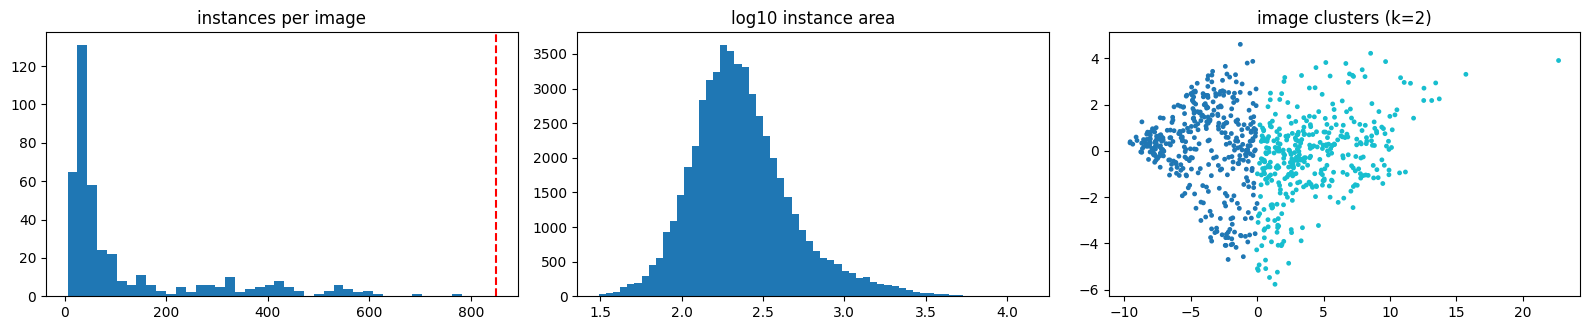

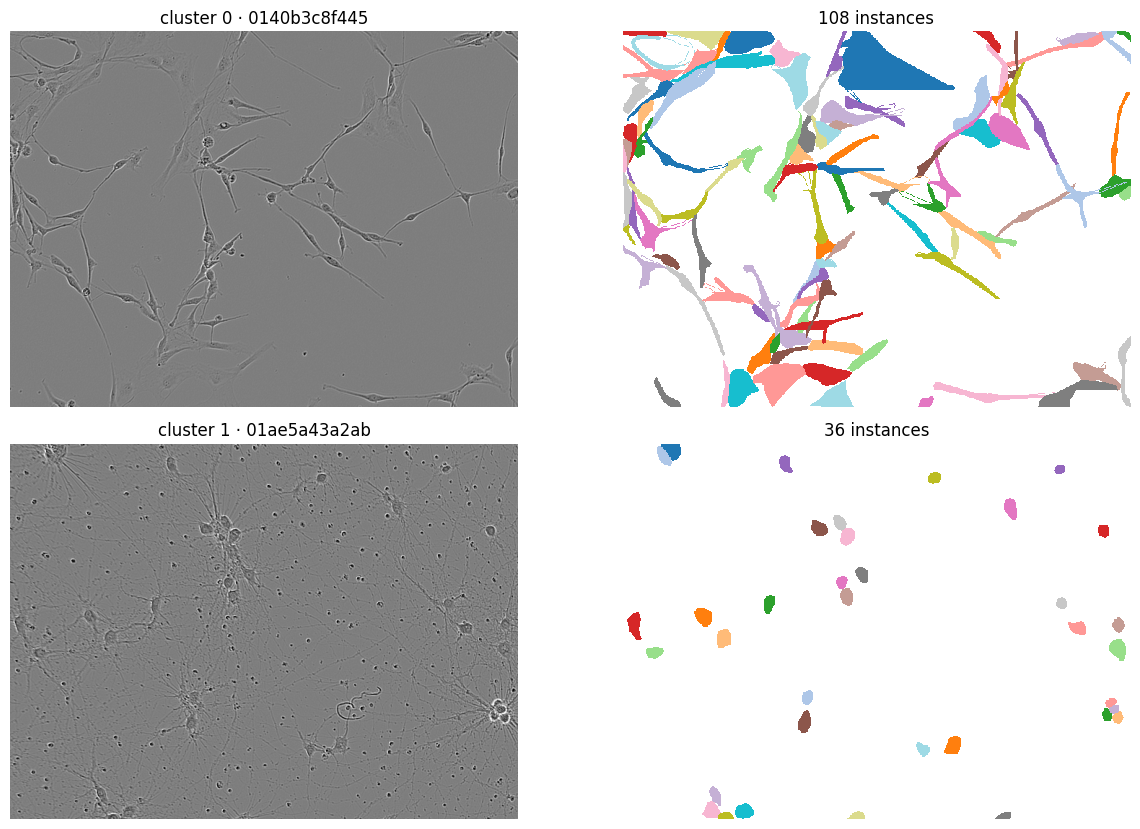

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.4))
ax[0].hist(counts, bins=40); ax[0].set_title("instances per image"); ax[0].axvline(CFG.BOX_DET_PER_IMG, c="r", ls="--")
ax[1].hist(np.log10(areas + 1), bins=60); ax[1].set_title("log10 instance area")
ax[2].scatter(Xp[:, 0], Xp[:, 1], c=KM.labels_, s=6, cmap="tab10"); ax[2].set_title(f"image clusters (k={BEST_K})")
plt.tight_layout(); plt.savefig(ART / "fig_stats.png", dpi=110); plt.show()

def overlay(iid, folder):
    with Image.open(Path(folder) / f"{iid}.png") as im:
        img = np.asarray(im.convert("L"))
    lab = np.zeros(CFG.IMG_H * CFG.IMG_W, dtype=np.int32)
    for k, f in enumerate(INST.get(iid, []), 1): lab[f] = k
    return img, lab.reshape(CFG.IMG_H, CFG.IMG_W)

show = []
for c in range(BEST_K):
    cand = [i for i in TRAIN_IDS if CLUSTER.get(i) == c]
    if cand: show.append((c, cand[0]))
fig, ax = plt.subplots(len(show), 2, figsize=(13, 4.2 * len(show)), squeeze=False)
for r, (c, iid) in enumerate(show):
    img, lab = overlay(iid, TRAIN_DIR)
    ax[r][0].imshow(img, cmap="gray"); ax[r][0].set_title(f"cluster {c} · {iid}"); ax[r][0].axis("off")
    ax[r][1].imshow(np.ma.masked_where(lab == 0, lab % 20), cmap="tab20", interpolation="nearest")
    ax[r][1].set_title(f"{lab.max()} instances"); ax[r][1].axis("off")
plt.tight_layout(); plt.savefig(ART / "fig_clusters.png", dpi=100); plt.show()

## 7 · Competition metric — ISOLATED

> Stated rule: *greedy one-to-one matching between predicted and ground-truth masks; a match counts
> if Dice ≥ 0.50; the final score is the mean Dice across all test images.*
>
> That still leaves the **per-image aggregation** ambiguous. Four candidates are computed; the one
> named in `CFG.PRIMARY_METRIC` drives checkpoint selection and threshold tuning. **Replace this
> cell with the official reference implementation as soon as it is available.**

| variant | per-image formula |
|---|---|
| `sum_over_max` | `Σ dice(matched) / max(n_gt, n_pred)` |
| `pq_like` | `Σ dice(matched) / (TP + FP + FN)` |
| `f1` | `2·TP / (2·TP + FP + FN)` |
| `mean_matched` | `Σ dice(matched) / TP` (no penalty for FP/FN — diagnostic only) |

In [12]:
from scipy.sparse import csr_matrix

def _sparse(flats, npix):
    if len(flats) == 0:
        return csr_matrix((0, npix), dtype=np.float32)
    indptr = np.zeros(len(flats) + 1, dtype=np.int64)
    indptr[1:] = np.cumsum([f.size for f in flats])
    indices = np.concatenate(flats).astype(np.int64) if len(flats) else np.empty(0, np.int64)
    return csr_matrix((np.ones(indices.size, np.float32), indices, indptr), shape=(len(flats), npix))

def dice_matrix(gt_flats, pred_flats, npix):
    A, B = _sparse(gt_flats, npix), _sparse(pred_flats, npix)
    if A.shape[0] == 0 or B.shape[0] == 0:
        return np.zeros((A.shape[0], B.shape[0]), np.float32)
    inter = np.asarray((A @ B.T).todense(), dtype=np.float32)
    a = np.array([f.size for f in gt_flats], np.float32)[:, None]
    b = np.array([f.size for f in pred_flats], np.float32)[None, :]
    return 2.0 * inter / np.maximum(a + b, 1e-6)

def greedy_match(D, thr):
    # strict one-to-one: each gt and each pred used at most once
    n, m = D.shape
    if n == 0 or m == 0: return 0, 0.0
    ii, jj = np.nonzero(D >= thr)
    if ii.size == 0: return 0, 0.0
    order = np.argsort(-D[ii, jj], kind="stable")
    gu = np.zeros(n, bool); pu = np.zeros(m, bool)
    tp, s = 0, 0.0
    for k in order:
        i, j = ii[k], jj[k]
        if gu[i] or pu[j]: continue
        gu[i] = pu[j] = True; tp += 1; s += float(D[i, j])
    return tp, s

def score_image(gt_flats, pred_flats, npix, thr=None):
    thr = CFG.DICE_MATCH_THR if thr is None else thr
    ngt, npr = len(gt_flats), len(pred_flats)
    if ngt == 0 and npr == 0:
        return dict(sum_over_max=1.0, pq_like=1.0, f1=1.0, mean_matched=1.0, tp=0, fp=0, fn=0)
    D = dice_matrix(gt_flats, pred_flats, npix)
    tp, s = greedy_match(D, thr)
    fp, fn = npr - tp, ngt - tp
    return dict(
        sum_over_max = s / max(max(ngt, npr), 1),
        pq_like      = s / max(tp + fp + fn, 1),
        f1           = 2 * tp / max(2 * tp + fp + fn, 1),
        mean_matched = s / tp if tp else 0.0,
        tp=tp, fp=fp, fn=fn)

def score_dataset(gt_dict, pred_dict, npix):
    keys = list(gt_dict.keys())
    per = [score_image(gt_dict[k], pred_dict.get(k, []), npix) for k in keys]
    out = {v: float(np.mean([p[v] for p in per])) for v in ("sum_over_max", "pq_like", "f1", "mean_matched")}
    out.update(tp=int(sum(p["tp"] for p in per)), fp=int(sum(p["fp"] for p in per)), fn=int(sum(p["fn"] for p in per)))
    return out

# ---- unit tests ----
NPIX = CFG.IMG_H * CFG.IMG_W
_id = TRAIN_IDS[0] if TRAIN_IDS[0] in INST else list(INST)[0]
g = INST[_id]
t1 = score_image(g, g, NPIX)
t2 = score_image(g, [], NPIX)
t3 = score_image(g, g + g, NPIX)                       # duplicated predictions -> FP penalty
t4 = score_image(g, g[: max(1, len(g)//2)], NPIX)      # half recall
print("perfect         :", {k: round(v, 4) for k, v in t1.items() if isinstance(v, float)})
print("no predictions  :", {k: round(v, 4) for k, v in t2.items() if isinstance(v, float)})
print("duplicated preds:", {k: round(v, 4) for k, v in t3.items() if isinstance(v, float)}, "<- must drop vs perfect")
print("half the preds  :", {k: round(v, 4) for k, v in t4.items() if isinstance(v, float)})
assert abs(t1["sum_over_max"] - 1.0) < 1e-6 and t2["sum_over_max"] == 0.0 and t3["sum_over_max"] < 0.6
assert t1["tp"] == len(g) and t3["fp"] == len(g)
print("\nmetric unit tests passed. PRIMARY_METRIC =", CFG.PRIMARY_METRIC)

perfect         : {'sum_over_max': 1.0, 'pq_like': 1.0, 'f1': 1.0, 'mean_matched': 1.0}
no predictions  : {'sum_over_max': 0.0, 'pq_like': 0.0, 'f1': 0.0, 'mean_matched': 0.0}
duplicated preds: {'sum_over_max': 0.5, 'pq_like': 0.5, 'f1': 0.6667, 'mean_matched': 1.0} <- must drop vs perfect
half the preds  : {'sum_over_max': 0.5, 'pq_like': 0.5, 'f1': 0.6667, 'mean_matched': 1.0}

metric unit tests passed. PRIMARY_METRIC = sum_over_max


## 8 · Split (stratified by cluster × density)

In [13]:
from sklearn.model_selection import train_test_split

lab_ids = [i for i in TRAIN_IDS if i in INST]
dens = np.array([len(INST[i]) for i in lab_ids])
bins = np.digitize(dens, np.percentile(dens, [33, 66]))
strat = [f"{CLUSTER.get(i, -1)}_{b}" for i, b in zip(lab_ids, bins)]
vc = Counter(strat)
strat = [s if vc[s] >= 2 else "rare" for s in strat]

tr_ids, va_ids = train_test_split(lab_ids, test_size=CFG.VAL_FRACTION,
                                  random_state=CFG.SEED, stratify=strat)
if CFG.SMOKE_TEST:
    tr_ids, va_ids = tr_ids[:24], va_ids[:10]
print(f"train {len(tr_ids)} | val {len(va_ids)}")
print("val cluster distribution :", Counter(CLUSTER.get(i, -1) for i in va_ids))
print("train mean instances", round(np.mean([len(INST[i]) for i in tr_ids]), 1),
      "| val mean instances", round(np.mean([len(INST[i]) for i in va_ids]), 1))
GT_VAL = {i: INST[i] for i in va_ids}

train 24 | val 10
val cluster distribution : Counter({1: 6, 0: 4})
train mean instances 167.2 | val mean instances 203.4


## 9 · Data pipeline

Pure-numpy augmentation (no Albumentations version risk). Boxes are recomputed from masks after every transform, so they can never desync.

batch: [(3, 520, 704), (3, 520, 704)] | instances: [174, 600]
mask target memory per batch: 283 MB (uint8)


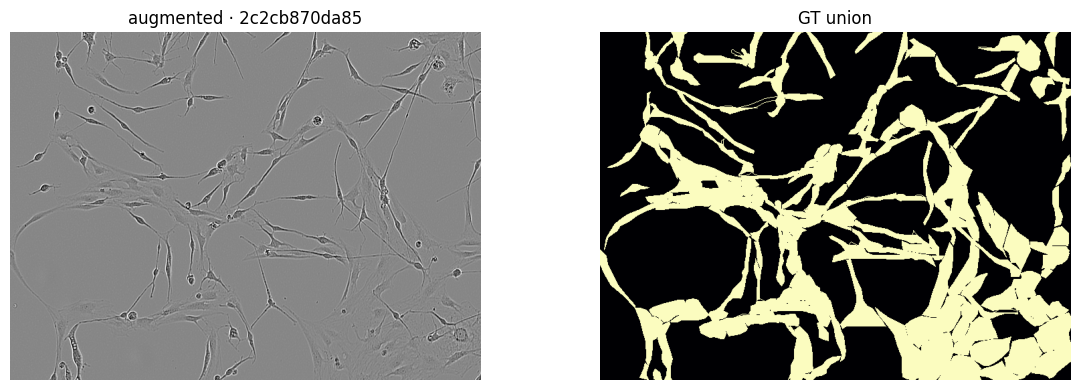

In [14]:
from torch.utils.data import Dataset, DataLoader

def load_gray01(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("L"), dtype=np.float32) / 255.0

class CellDS(Dataset):
    def __init__(self, ids, img_dir, train=True):
        self.ids, self.dir, self.train = ids, Path(img_dir), train
    def __len__(self): return len(self.ids)

    def _aug(self, img, masks):
        if random.random() < CFG.AUG_HFLIP:
            img = img[:, ::-1]; masks = masks[:, :, ::-1]
        if random.random() < CFG.AUG_VFLIP:
            img = img[::-1]; masks = masks[:, ::-1]
        if random.random() < CFG.AUG_ROT90:
            k = random.choice([1, 2, 3])
            img = np.rot90(img, k); masks = np.rot90(masks, k, axes=(1, 2))
        img = np.ascontiguousarray(img); masks = np.ascontiguousarray(masks)
        if random.random() < CFG.AUG_BRIGHTNESS_CONTRAST:
            img = np.clip((img - 0.5) * random.uniform(0.85, 1.18) + 0.5 + random.uniform(-0.10, 0.10), 0, 1)
        if random.random() < CFG.AUG_GAMMA:
            img = np.clip(img, 1e-4, 1) ** random.uniform(0.75, 1.35)
        if random.random() < CFG.AUG_NOISE:
            img = np.clip(img + np.random.normal(0, random.uniform(0.005, 0.02), img.shape), 0, 1)
        return img.astype(np.float32), masks

    def __getitem__(self, i):
        iid = self.ids[i]
        img = load_gray01(self.dir / f"{iid}.png")
        flats = INST[iid]
        if len(flats) > CFG.MAX_INSTANCES_TRAIN:
            flats = [flats[j] for j in np.random.choice(len(flats), CFG.MAX_INSTANCES_TRAIN, replace=False)]
        masks = np.zeros((len(flats), CFG.IMG_H * CFG.IMG_W), dtype=np.uint8)
        for k, f in enumerate(flats): masks[k, f] = 1
        masks = masks.reshape(len(flats), CFG.IMG_H, CFG.IMG_W)
        if self.train:
            img, masks = self._aug(img, masks)
        h, w = img.shape
        keep, boxes = [], []
        for k in range(masks.shape[0]):
            ys, xs = np.nonzero(masks[k])
            if ys.size < CFG.MIN_GT_AREA: continue
            x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
            if x1 <= x0 or y1 <= y0: continue
            keep.append(k); boxes.append([x0, y0, x1 + 1, y1 + 1])
        masks = masks[keep] if keep else np.zeros((0, h, w), np.uint8)
        target = dict(
            boxes=torch.as_tensor(np.array(boxes, np.float32).reshape(-1, 4)),
            labels=torch.ones((len(keep),), dtype=torch.int64),
            masks=torch.as_tensor(masks, dtype=torch.uint8),
            image_id=torch.tensor([i]))
        return torch.from_numpy(img).unsqueeze(0).repeat(3, 1, 1), target, iid

def collate(b): return tuple(zip(*b))

dl_train = DataLoader(CellDS(tr_ids, TRAIN_DIR, True), batch_size=CFG.BATCH_SIZE, shuffle=True,
                      num_workers=CFG.NUM_WORKERS, collate_fn=collate, pin_memory=True,
                      persistent_workers=CFG.NUM_WORKERS > 0, drop_last=True)
dl_val = DataLoader(CellDS(va_ids, TRAIN_DIR, False), batch_size=1, shuffle=False,
                    num_workers=CFG.NUM_WORKERS, collate_fn=collate)

imgs, tgts, iids = next(iter(dl_train))
print("batch:", [tuple(x.shape) for x in imgs], "| instances:", [int(t['masks'].shape[0]) for t in tgts])
print("mask target memory per batch: "
      f"{sum(t['masks'].numel() for t in tgts)/1e6:.0f} MB (uint8)")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(imgs[0][0].numpy(), cmap="gray"); ax[0].set_title(f"augmented · {iids[0]}"); ax[0].axis("off")
ax[1].imshow(tgts[0]["masks"].numpy().max(0), cmap="magma"); ax[1].set_title("GT union"); ax[1].axis("off")
plt.tight_layout(); plt.savefig(ART / "fig_batch.png", dpi=100); plt.show()

## 10 · Model

Three deliberate changes vs. the provided baseline:

1. **No double normalization.** Images are fed in `[0,1]`; `GeneralizedRCNNTransform` does the only
   normalization, using dataset statistics rather than ImageNet's.
2. **Detection capacity** raised to match the real instance-count distribution (the baseline's cap of
   100 is below the *mean* number of cells per image).
3. **Anchors** derived from the GT box distribution, keeping 3 aspect ratios per location so the
   pretrained RPN head weights remain usable.

`WEIGHTS_MODE` is a config flag, not a decision: `"coco"` matches the official baseline,
`"imagenet_bb"` is the strictly rules-safe reading. **Confirm with a TA which is intended.**

In [15]:
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection import roi_heads as _rh

_orig_mask_loss = _rh.maskrcnn_loss

def maskrcnn_loss_bce_dice(mask_logits, proposals, gt_masks, gt_labels, mask_matched_idxs):
    disc = mask_logits.shape[-1]
    labels = torch.cat([l[i] for l, i in zip(gt_labels, mask_matched_idxs)], dim=0)
    targets = torch.cat([_rh.project_masks_on_boxes(m, p, i, disc)
                         for m, p, i in zip(gt_masks, proposals, mask_matched_idxs)], dim=0)
    if targets.numel() == 0:
        return mask_logits.sum() * 0
    idx = torch.arange(labels.shape[0], device=labels.device)
    logits = mask_logits[idx, labels].float()
    t = targets.float()
    bce = F.binary_cross_entropy_with_logits(logits, t)
    p = torch.sigmoid(logits)
    inter = (p * t).sum(dim=(1, 2)); den = p.sum(dim=(1, 2)) + t.sum(dim=(1, 2))
    dice = 1.0 - (2 * inter + 1.0) / (den + 1.0)
    return CFG.BCE_W * bce + CFG.DICE_W * dice.mean()

_rh.maskrcnn_loss = maskrcnn_loss_bce_dice if CFG.MASK_LOSS == "bce+dice" else _orig_mask_loss
print("mask loss:", CFG.MASK_LOSS)

def build_model():
    kw = dict(box_detections_per_img=CFG.BOX_DET_PER_IMG,
              min_size=min(CFG.MIN_SIZE_TRAIN), max_size=CFG.MAX_SIZE,
              rpn_batch_size_per_image=CFG.RPN_BATCH_PER_IMG,
              box_batch_size_per_image=CFG.BOX_BATCH_PER_IMG)
    if CFG.ARCH == "v2":
        from torchvision.models.detection import maskrcnn_resnet50_fpn_v2, MaskRCNN_ResNet50_FPN_V2_Weights
        ctor, W = maskrcnn_resnet50_fpn_v2, MaskRCNN_ResNet50_FPN_V2_Weights.COCO_V1
    else:
        from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
        ctor, W = maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights.COCO_V1
    from torchvision.models import ResNet50_Weights
    if CFG.WEIGHTS_MODE == "coco":
        m = ctor(weights=W, trainable_backbone_layers=CFG.TRAINABLE_BB_LAYERS, **kw)
        src = "COCO detector (matches the official baseline)"
    else:
        m = ctor(weights=None, weights_backbone=ResNet50_Weights.IMAGENET1K_V1,
                 trainable_backbone_layers=CFG.TRAINABLE_BB_LAYERS, **kw)
        src = "ImageNet backbone only (heads from scratch)"

    inf = m.roi_heads.box_predictor.cls_score.in_features
    m.roi_heads.box_predictor = FastRCNNPredictor(inf, 2)
    infm = m.roi_heads.mask_predictor.conv5_mask.in_channels
    m.roi_heads.mask_predictor = MaskRCNNPredictor(infm, 256, 2)

    if CFG.ANCHOR_SIZES is not None:
        ar = CFG.ASPECT_RATIOS if CFG.ASPECT_RATIOS is not None else (0.5, 1.0, 2.0)
        m.rpn.anchor_generator = AnchorGenerator(sizes=tuple(CFG.ANCHOR_SIZES),
                                                 aspect_ratios=tuple(tuple(ar) for _ in CFG.ANCHOR_SIZES))
    if CFG.NORMALIZE_WITH_DATASET_STATS:
        m.transform.image_mean = [DS_MEAN] * 3
        m.transform.image_std = [DS_STD] * 3
    m.transform.min_size = tuple(CFG.MIN_SIZE_TRAIN)
    m.transform.max_size = CFG.MAX_SIZE
    print("weights      :", src)
    print("anchors      :", m.rpn.anchor_generator.sizes, m.rpn.anchor_generator.aspect_ratios[0])
    print("norm mean/std:", m.transform.image_mean[0], m.transform.image_std[0])
    print("det/img      :", m.roi_heads.detections_per_img)
    return m

model = build_model().to(DEVICE)
n_par = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable params: {n_par/1e6:.1f} M")

mask loss: bce+dice
Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:01<00:00, 162MB/s]  


weights      : COCO detector (matches the official baseline)
anchors      : ((12,), (16,), (20,), (28,), (60,)) (0.62, 1.0, 1.58)
norm mean/std: 0.5018043600598745 0.05476371502627272
det/img      : 850
trainable params: 45.9 M


## 11 · Training (AMP, warmup + cosine, grad accumulation, metric-based selection, resume-safe)

In [16]:
def set_infer_cfg(m, score_thr, max_det, pre=None, post=None):
    m.roi_heads.score_thresh = score_thr
    m.roi_heads.detections_per_img = max_det
    m.rpn._pre_nms_top_n["testing"] = pre or CFG.RPN_PRE_TEST
    m.rpn._post_nms_top_n["testing"] = post or CFG.RPN_POST_TEST
    m.transform.min_size = (CFG.MIN_SIZE_TEST,)

def autocast():
    try:    return torch.amp.autocast("cuda", enabled=CFG.AMP)
    except Exception: return torch.cuda.amp.autocast(enabled=CFG.AMP)

@torch.no_grad()
def quick_eval(m, score_thr=None, mask_thr=0.5, min_area=0):
    m.eval(); set_infer_cfg(m, score_thr or CFG.EVAL_SCORE_THR, CFG.EVAL_MAX_DET)
    preds = {}
    for imgs, tgts, iids in dl_val:
        with autocast():
            out = m([imgs[0].to(DEVICE, non_blocking=True)])[0]
        msk = out["masks"][:, 0].float().cpu().numpy()
        occ = np.zeros(NPIX, bool); keep = []
        for mm in msk:
            flat = np.flatnonzero(mm.reshape(-1) > mask_thr)
            flat = flat[~occ[flat]]
            if flat.size < min_area: continue
            occ[flat] = True; keep.append(flat.astype(np.int32))
        preds[iids[0]] = keep
    m.transform.min_size = tuple(CFG.MIN_SIZE_TRAIN); m.train()
    return score_dataset(GT_VAL, preds, NPIX)

params = [
    {"params": [p for n, p in model.named_parameters() if p.requires_grad and n.startswith("backbone")],
     "lr": CFG.LR * CFG.BACKBONE_LR_MULT},
    {"params": [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("backbone")],
     "lr": CFG.LR},
]
opt = torch.optim.AdamW(params, lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)
steps_per_epoch = max(1, len(dl_train) // CFG.ACCUM_STEPS)
total_steps = steps_per_epoch * CFG.EPOCHS

def lr_at(step):
    if step < CFG.WARMUP_STEPS: return (step + 1) / CFG.WARMUP_STEPS
    p = (step - CFG.WARMUP_STEPS) / max(1, total_steps - CFG.WARMUP_STEPS)
    return 0.5 * (1 + math.cos(math.pi * min(p, 1.0)))

sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_at)
try:    scaler = torch.amp.GradScaler("cuda", enabled=CFG.AMP)
except Exception: scaler = torch.cuda.amp.GradScaler(enabled=CFG.AMP)

BEST = CKPT / "best.pt"; LAST = CKPT / "last.pt"
start_epoch, best_score, log = 1, -1.0, []
if LAST.exists():   # resume after an interrupted session (Kaggle file persistence)
    ck = torch.load(LAST, map_location="cpu")
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    start_epoch, best_score, log = ck["epoch"] + 1, ck["best"], ck["log"]
    print(f">>> resumed from epoch {ck['epoch']} (best {best_score:.4f})")

In [17]:
gstep = (start_epoch - 1) * steps_per_epoch
for epoch in range(start_epoch, CFG.EPOCHS + 1):
    model.train(); model.transform.min_size = tuple(CFG.MIN_SIZE_TRAIN)
    t0, agg = time.time(), defaultdict(float)
    opt.zero_grad(set_to_none=True)
    for it, (imgs, tgts, _) in enumerate(dl_train, 1):
        imgs = [i.to(DEVICE, non_blocking=True) for i in imgs]
        tgts = [{k: (v.to(DEVICE, non_blocking=True) if torch.is_tensor(v) else v) for k, v in t.items()} for t in tgts]
        if any(t["boxes"].shape[0] == 0 for t in tgts): continue
        with autocast():
            ld = model(imgs, tgts)
            loss = sum(ld.values())
        if not torch.isfinite(loss):
            print(f"  !! non-finite loss at it {it}, skipping"); opt.zero_grad(set_to_none=True); continue
        scaler.scale(loss / CFG.ACCUM_STEPS).backward()
        for k, v in ld.items(): agg[k] += float(v)
        agg["total"] += float(loss)
        if it % CFG.ACCUM_STEPS == 0:
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
            sched.step(); gstep += 1
        if it % 50 == 0:
            print(f"  e{epoch} it{it}/{len(dl_train)} loss {agg['total']/it:.3f} "
                  f"mask {agg['loss_mask']/it:.3f} lr {sched.get_last_lr()[-1]:.2e} "
                  f"{(time.time()-t0)/it:.2f}s/it", flush=True)
    row = dict(epoch=epoch, **{k: v / max(it, 1) for k, v in agg.items()},
               lr=sched.get_last_lr()[-1], sec=round(time.time() - t0, 1))
    if epoch >= CFG.EVAL_START_EPOCH and epoch % CFG.EVAL_EVERY == 0:
        m = quick_eval(model)
        row.update({f"val_{k}": v for k, v in m.items()})
        cur = m[CFG.PRIMARY_METRIC]
        if cur > best_score:
            best_score = cur
            torch.save({"model": model.state_dict(), "cfg": {k: str(v) for k, v in vars(CFG).items() if k.isupper()},
                        "score": cur, "epoch": epoch}, BEST)
            row["saved_best"] = True
    log.append(row)
    print(f"[epoch {epoch}] " + " ".join(f"{k}={v:.4f}" if isinstance(v, float) else f"{k}={v}"
                                          for k, v in row.items()), flush=True)
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                "scaler": scaler.state_dict(), "epoch": epoch, "best": best_score, "log": log}, LAST)
    pd.DataFrame(log).to_csv(ART / "train_log.csv", index=False)
    gc.collect(); torch.cuda.empty_cache()

print(f"\n>>> best val {CFG.PRIMARY_METRIC} = {best_score:.4f}")
print(pd.DataFrame(log).to_string(index=False))
STATS["best_val_score"] = float(best_score)

[epoch 1] epoch=1 loss_classifier=0.5963 loss_box_reg=0.1792 loss_mask=1.9723 loss_objectness=1.6572 loss_rpn_box_reg=0.4090 total=4.8140 lr=0.0000 sec=111.9000 val_sum_over_max=0.0000 val_pq_like=0.0000 val_f1=0.0000 val_mean_matched=0.0000 val_tp=0 val_fp=4000 val_fn=2034 saved_best=True
[epoch 2] epoch=2 loss_classifier=0.5618 loss_box_reg=0.1735 loss_mask=1.9088 loss_objectness=1.6808 loss_rpn_box_reg=0.3910 total=4.7160 lr=0.0000 sec=20.2000 val_sum_over_max=0.0005 val_pq_like=0.0003 val_f1=0.0011 val_mean_matched=0.1058 val_tp=4 val_fp=3996 val_fn=2030 saved_best=True

>>> best val sum_over_max = 0.0005
 epoch  loss_classifier  loss_box_reg  loss_mask  loss_objectness  loss_rpn_box_reg    total       lr   sec  val_sum_over_max  val_pq_like  val_f1  val_mean_matched  val_tp  val_fp  val_fn  saved_best
     1         0.596320      0.179154   1.972323         1.657247          0.408996 4.814040 0.000002 111.9          0.000000      0.00000 0.00000          0.000000       0    4000  

## 12 · Cached validation predictions + threshold sweep

Inference is run **once** at a near-zero score threshold; soft masks are cached (cropped to the box,
quantised to `uint8`) so score / mask / min-area thresholds can be swept offline in seconds instead of
re-running the model per combination.

Because masks are painted in descending score order, raising the score threshold simply truncates the
list — higher-scored instances are unaffected. That prefix property is what makes the sweep exact.

In [18]:
if BEST.exists():
    model.load_state_dict(torch.load(BEST, map_location="cpu")["model"]); print("loaded best checkpoint")
model.to(DEVICE).eval()
set_infer_cfg(model, CFG.CACHE_SCORE_THR, CFG.CACHE_MAX_DET)

@torch.no_grad()
def cache_predictions(ids, img_dir):
    cache = {}
    for n, iid in enumerate(ids, 1):
        img = load_gray01(Path(img_dir) / f"{iid}.png")
        t = torch.from_numpy(img).unsqueeze(0).repeat(3, 1, 1).to(DEVICE)
        with autocast():
            out = model([t])[0]
        msk = out["masks"][:, 0].float().cpu().numpy()
        sc = out["scores"].float().cpu().numpy()
        ent = []
        for mm, s in zip(msk, sc):
            ys, xs = np.nonzero(mm > 0.05)
            if ys.size == 0: continue
            y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
            ent.append((float(s), int(y0), int(x0), (mm[y0:y1, x0:x1] * 255).astype(np.uint8)))
        ent.sort(key=lambda e: -e[0])
        cache[iid] = ent
        if n % 25 == 0: print(f"  cached {n}/{len(ids)}", flush=True)
    return cache

t0 = time.time(); VAL_CACHE = cache_predictions(va_ids, TRAIN_DIR)
print(f"cached in {time.time()-t0:.0f}s | mean raw detections/img: "
      f"{np.mean([len(v) for v in VAL_CACHE.values()]):.0f} "
      f"| mean GT/img: {np.mean([len(GT_VAL[i]) for i in va_ids]):.0f}")

def build_instances(entries, mask_thr, min_area, H, W):
    occ = np.zeros(H * W, bool); out = []
    for s, y0, x0, crop in entries:
        m = crop > int(mask_thr * 255)
        ys, xs = np.nonzero(m)
        if ys.size == 0: continue
        flat = (ys + y0).astype(np.int64) * W + (xs + x0)
        flat = flat[~occ[flat]]
        if flat.size < min_area: continue
        occ[flat] = True
        out.append((s, flat.astype(np.int32)))
    return out

loaded best checkpoint
cached in 19s | mean raw detections/img: 500 | mean GT/img: 203


In [19]:
rows = []
for mt in CFG.SWEEP_MASK_THR:
    for ma in MIN_AREA_GRID:
        built = {i: build_instances(VAL_CACHE[i], mt, ma, CFG.IMG_H, CFG.IMG_W) for i in va_ids}
        Dcache = {i: (dice_matrix(GT_VAL[i], [f for _, f in built[i]], NPIX),
                      np.array([s for s, _ in built[i]])) for i in va_ids}
        for st in CFG.SWEEP_SCORE_THR:
            per = []
            for i in va_ids:
                D, sc = Dcache[i]
                k = int((sc >= st).sum())
                Dk = D[:, :k]
                ngt, npr = D.shape[0], k
                tp, s = greedy_match(Dk, CFG.DICE_MATCH_THR) if npr else (0, 0.0)
                fp, fn = npr - tp, ngt - tp
                per.append(dict(sum_over_max=s / max(max(ngt, npr), 1),
                                pq_like=s / max(tp + fp + fn, 1),
                                f1=2 * tp / max(2 * tp + fp + fn, 1),
                                tp=tp, fp=fp, fn=fn, npred=npr))
            rows.append(dict(mask_thr=mt, min_area=ma, score_thr=st,
                             **{k: float(np.mean([p[k] for p in per])) for k in
                                ("sum_over_max", "pq_like", "f1", "npred")},
                             tp=int(sum(p["tp"] for p in per)), fp=int(sum(p["fp"] for p in per)),
                             fn=int(sum(p["fn"] for p in per))))
sweep = pd.DataFrame(rows).sort_values(CFG.PRIMARY_METRIC, ascending=False)
sweep.to_csv(ART / "sweep_results.csv", index=False)
print(sweep.head(12).to_string(index=False))

BESTP = sweep.iloc[0]
POST = dict(mask_thr=float(BESTP.mask_thr), min_area=int(BESTP.min_area), score_thr=float(BESTP.score_thr))
print("\n>>> best post-processing:", POST)
print(f">>> val  sum_over_max={BESTP.sum_over_max:.4f}  pq_like={BESTP.pq_like:.4f}  f1={BESTP.f1:.4f}")
print(f">>> default-ish (score .5 / mask .5) for comparison:")
base = sweep[(sweep.score_thr == 0.5) & (sweep.mask_thr == 0.5)]
print(base.head(3).to_string(index=False) if len(base) else "   (not in grid)")

# per-cluster thresholds, reported but not used unless enabled
pc = {}
for c in sorted(set(CLUSTER.get(i, -1) for i in va_ids)):
    sub = [i for i in va_ids if CLUSTER.get(i, -1) == c]
    if len(sub) < 4: continue
    best, bs = None, -1
    for mt in CFG.SWEEP_MASK_THR:
        for ma in MIN_AREA_GRID:
            built = {i: build_instances(VAL_CACHE[i], mt, ma, CFG.IMG_H, CFG.IMG_W) for i in sub}
            for st in CFG.SWEEP_SCORE_THR:
                pr = {i: [f for s, f in built[i] if s >= st] for i in sub}
                v = score_dataset({i: GT_VAL[i] for i in sub}, pr, NPIX)[CFG.PRIMARY_METRIC]
                if v > bs: bs, best = v, dict(mask_thr=mt, min_area=ma, score_thr=st)
    pc[c] = dict(n_val=len(sub), score=round(bs, 4), **best)
print("\nper-cluster optima (n_val is small — treat as diagnostic):")
print(pd.DataFrame(pc).T.to_string())
STATS["post"] = POST; STATS["per_cluster_post"] = {str(k): v for k, v in pc.items()}
STATS["sweep_top"] = sweep.head(5).to_dict("records")

 mask_thr  min_area  score_thr  sum_over_max  pq_like       f1  npred  tp   fp   fn
      0.4        82        0.3      0.001650 0.000945 0.003449  165.0  10 1640 2024
      0.4        82        0.1      0.001650 0.000943 0.003444  165.2  10 1642 2024
      0.4        82        0.2      0.001650 0.000943 0.003444  165.2  10 1642 2024
      0.4        30        0.3      0.001560 0.000922 0.003337  251.7  12 2505 2022
      0.4        30        0.1      0.001551 0.000919 0.003325  252.4  12 2512 2022
      0.4        30        0.2      0.001551 0.000919 0.003325  252.4  12 2512 2022
      0.5        82        0.2      0.000821 0.000482 0.001851  122.6   5 1221 2029
      0.5        82        0.1      0.000821 0.000482 0.001851  122.6   5 1221 2029
      0.5        82        0.3      0.000821 0.000482 0.001851  122.5   5 1220 2029
      0.5        30        0.3      0.000663 0.000378 0.001453  215.8   5 2153 2029
      0.5        30        0.2      0.000663 0.000378 0.001453  216.3   5 21

## 13 · Test inference & submission

In [20]:
set_infer_cfg(model, CFG.CACHE_SCORE_THR, CFG.CACHE_MAX_DET)
t0 = time.time(); TEST_CACHE = cache_predictions(TEST_IDS, TEST_DIR)
print(f"test inference {time.time()-t0:.0f}s")

sub_rows = []
n_inst = []
for iid in TEST_IDS:
    p = POST
    if CFG.PER_CLUSTER_THRESHOLDS and CLUSTER.get(iid, -1) in [int(k) for k in STATS["per_cluster_post"]]:
        p = STATS["per_cluster_post"][str(CLUSTER[iid])]
    inst = [f for s, f in build_instances(TEST_CACHE[iid], p["mask_thr"], p["min_area"], CFG.IMG_H, CFG.IMG_W)
            if s >= p["score_thr"]]
    n_inst.append(len(inst))
    if not inst:
        sub_rows.append((iid, "-1")); continue
    for f in inst:
        m = np.zeros(CFG.IMG_H * CFG.IMG_W, bool); m[f] = True
        sub_rows.append((iid, rle_encode(m)))

sub = pd.DataFrame(sub_rows, columns=[ID_COL, ANN_COL])
if any(c.lower() in ("idx", "unnamed: 0") for c in OTHER_COLS):
    idxc = [c for c in OTHER_COLS if c.lower() in ("idx", "unnamed: 0")][0]
    sub.insert(0, idxc, range(len(sub)))
sub.to_csv("/kaggle/working/submission.csv", index=False)
shutil.copy("/kaggle/working/submission.csv", ART / "submission.csv")

print("submission columns:", sub.columns.tolist(), "| rows:", len(sub))
print(sub.head(3).to_string())
print(f"\npredicted instances/image: mean {np.mean(n_inst):.1f} min {min(n_inst)} max {max(n_inst)} "
      f"| GT train mean {counts.mean():.1f}")
print("images with no prediction:", int(sum(1 for n in n_inst if n == 0)))
assert set(sub[ID_COL]) == set(TEST_IDS), "submission is missing test image ids"

# overlap validation (Kaggle usually rejects overlapping masks)
chk = 0
for iid in TEST_IDS[:20]:
    acc = np.zeros(CFG.IMG_H * CFG.IMG_W, np.int16)
    for r in sub[sub[ID_COL] == iid][ANN_COL]:
        if r == "-1": continue
        acc[rle_decode_flat(r, CFG.IMG_H, CFG.IMG_W, "C")] += 1
    chk += int((acc > 1).sum())
print("overlapping predicted pixels in first 20 test images:", chk, "(must be 0)")
STATS["test_pred_counts"] = dict(mean=float(np.mean(n_inst)), min=int(min(n_inst)), max=int(max(n_inst)))

  cached 25/182
  cached 50/182
  cached 75/182
  cached 100/182
  cached 125/182
  cached 150/182
  cached 175/182
test inference 339s
submission columns: ['Unnamed: 0', 'id', 'annotation'] | rows: 20133
   Unnamed: 0            id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      annotation
0           0  0030fd0e6378                                                                                                                    

## 14 · Report — copy this back

In [21]:
STATS["cfg"] = {k: str(v) for k, v in vars(CFG).items() if k.isupper()}
STATS["train_log"] = log
with open(ART / "eda_stats.json", "w") as f:
    json.dump(STATS, f, indent=2, default=str)

lines = [
    "# Run report",
    f"- smoke_test: {CFG.SMOKE_TEST} | arch: {CFG.ARCH} | weights: {CFG.WEIGHTS_MODE} | mask_loss: {CFG.MASK_LOSS}",
    f"- csv columns: {STATS['csv_columns']} | cell_type present: {STATS['has_cell_type']}",
    f"- rle order: {STATS['rle_order']} | GT overlap images: {STATS['gt_overlap_images_pct']:.1f}%",
    f"- images: {STATS['n_train_images']} train / {STATS['n_test_images']} test / {STATS['n_unlabeled']} unlabeled",
    f"- instances/img p50/p95/p99/max: {STATS['counts']['p50']:.0f}/{STATS['counts']['p95']:.0f}/"
    f"{STATS['counts']['p99']:.0f}/{STATS['counts']['p100']:.0f}",
    f"- area p1/p5/p50/p95: {STATS['areas']['p1']:.0f}/{STATS['areas']['p5']:.0f}/"
    f"{STATS['areas']['p50']:.0f}/{STATS['areas']['p95']:.0f}",
    f"- box side p5/p50/p95: {STATS['box_side']['p5']:.0f}/{STATS['box_side']['p50']:.0f}/{STATS['box_side']['p95']:.0f}",
    f"- anchors: {CFG.ANCHOR_SIZES} ratios {CFG.ASPECT_RATIOS} | det/img {CFG.BOX_DET_PER_IMG}",
    f"- dataset mean/std: {DS_MEAN:.4f}/{DS_STD:.4f}",
    f"- clusters k={STATS['best_k']} silhouette {STATS['silhouette']}",
    f"- best val {CFG.PRIMARY_METRIC}: {STATS.get('best_val_score')}",
    f"- best post-processing: {STATS['post']}",
    f"- val at best: sum_over_max={BESTP.sum_over_max:.4f} pq_like={BESTP.pq_like:.4f} f1={BESTP.f1:.4f}",
    f"- test predictions/img: {STATS['test_pred_counts']}",
    "",
    "## Open questions",
    "1. Official Dice@0.5 aggregation (paste the reference implementation).",
    "2. Is the COCO-pretrained detector permitted, or ImageNet backbone only?",
    "3. Submission column schema — confirmed against the leaderboard?",
]
open(ART / "REPORT.md", "w").write("\n".join(lines))
print("\n".join(lines))
print("\nartifacts:", [p.name for p in sorted(ART.iterdir())])

# Run report
- smoke_test: True | arch: v2 | weights: coco | mask_loss: bce+dice
- csv columns: ['Unnamed: 0', 'id', 'annotation'] | cell_type present: False
- rle order: C | GT overlap images: 91.7%
- images: 424 train / 182 test / 1972 unlabeled
- instances/img p50/p95/p99/max: 48/504/593/782
- area p1/p5/p50/p95: 53/82/215/920
- box side p5/p50/p95: 11/19/54
- anchors: ((12,), (16,), (20,), (28,), (60,)) ratios (0.62, 1.0, 1.58) | det/img 850
- dataset mean/std: 0.5018/0.0548
- clusters k=2 silhouette {2: 0.4203592958718911, 3: 0.3648181272799571, 4: 0.358939458950008, 5: 0.33039122105720714}
- best val sum_over_max: 0.0004810721634692943
- best post-processing: {'mask_thr': 0.4, 'min_area': 82, 'score_thr': 0.3}
- val at best: sum_over_max=0.0017 pq_like=0.0009 f1=0.0034
- test predictions/img: {'mean': 110.5989010989011, 'min': 0, 'max': 341}

## Open questions
1. Official Dice@0.5 aggregation (paste the reference implementation).
2. Is the COCO-pretrained detector permitted, or I